# CellTransformer2 on BARseq whole-cortex data

This notebook trains CellTransformer2 on the BARseq whole-cortex pilot brain (Chen et al.; 1,161,387 cells
in 40 sections, 106 sequencing targets, 46 cell types) with the same native commands as `03_custom_dataset.ipynb`:
`celltransformer-preprocess` → `celltransformer-train` → `celltransformer-extract` → `celltransformer-smooth` → `celltransformer-cluster`.
The steps and cells mirror notebook 03, so what you learn here carries over to your own data.
The differences are the data and three settings chosen for it: 310 µm neighborhoods (Step 6),
smoothing with σ = 100 µm (Step 10) and k = 63, 252 and 564 (Step 11).

**Before you start:**
- About 1 GB of storage for the BARseq files, which Step 1 downloads (~0.83 GB), checksums and converts
  under `DATA_ROOT/data/`, and roughly 2 GB for everything this notebook writes to `WORK_DIR`.
- Two environments, both with the package installed (`pip install -e .` from the repository):
  a training environment (this notebook's kernel, with `torchdata>=0.11`), and a RAPIDS environment
  with cuML, used for smoothing and clustering.
- Linux x86_64 and an NVIDIA GPU with bfloat16 support.
- Notebook support and HTML reporting are included in the installed CellTransformer2 package.

**Input contract.** Every later step reads the standard input written in Step 3, one pair per section:
an `.h5ad` of raw counts (cells × genes) in `layers['raw']` and a paired `.parquet` of the same cells, in the same order,
with columns `section`, `x`, `y` (µm) and `cell_type`. Row *i* of the metadata must describe row *i* of
the count matrix.

## Step 1: set paths and dataset columns
● TIMING <1 min, plus the first download (~0.83 GB)

Set `DATA_ROOT`, `WORK_DIR` and `RAPIDS_BIN`, then run the next cell to download the BARseq files into
`DATA_ROOT/data/raw/` and convert them into `DATA_ROOT/data/converted/` (finished work is skipped).
The column names below are those of the converted BARseq cell table. All 40 sections are used.
`VALID_SECTIONS` (Slice04, Slice18, Slice26 and Slice30) are held out entirely from training and used
only for the validation loss (split by section, not by cell, so validation measures generalization to unseen tissue).

In [1]:
import sys
from pathlib import Path

import anndata as ad
import numpy as np
import pandas as pd
import yaml

from celltransformer.notebooks import helper

#where the BARseq files go (the next cell downloads them into DATA_ROOT/data/raw/ and converts them into DATA_ROOT/data/converted/)
DATA_ROOT = Path("~/barseq_data").expanduser().resolve()
RAW_H5AD = DATA_ROOT / "data/converted/expression_raw.h5ad"
RAW_METADATA = DATA_ROOT / "data/converted/cells.parquet"

#REPLACE WITH YOUR DATA: metadata column names
CELL_ID_COL = 'cell_id'
SECTION_COL = 'section'
CELL_TYPE_COL = 'cell_subclass'
X_COL = 'x_um'
Y_COL = 'y_um'
COORD_TO_UM = 1.0

#REPLACE WITH YOUR DATA: genes to drop (none for BARseq: the download already removes unused barcodes), matched on this var column
GENE_SYMBOL_COL = 'gene_symbol'
DROP_GENE_PREFIX = 'unused'

#REPLACE WITH YOUR DATA: sections to use and sections held out for validation
SECTIONS = ['Slice01', 'Slice02', 'Slice03', 'Slice04', 'Slice05', 'Slice06', 'Slice07', 'Slice08', 'Slice09', 'Slice10', 'Slice11', 'Slice12', 'Slice13', 'Slice14', 'Slice15', 'Slice16', 'Slice17', 'Slice18', 'Slice19', 'Slice20', 'Slice21', 'Slice22', 'Slice23', 'Slice24', 'Slice25', 'Slice26', 'Slice27', 'Slice28', 'Slice29', 'Slice30', 'Slice31', 'Slice32', 'Slice33', 'Slice34', 'Slice35', 'Slice36', 'Slice37', 'Slice38', 'Slice39', 'Slice40']
VALID_SECTIONS = ['Slice04', 'Slice18', 'Slice26', 'Slice30']

#working directory for everything this notebook writes
WORK_DIR = Path("~/ct2_runs/barseq").expanduser().resolve()

#bin/ directories of the two environments: this kernel's, and the RAPIDS one (set this)
DEV_BIN = Path(sys.executable).parent
#REPLACE WITH YOUR ENV: bin/ of celltransformer2-rapids; run `conda env list` and add /bin to its path
RAPIDS_BIN = Path("/path/to/rapids-env/bin").resolve()

#derived paths
INPUT_DIR = WORK_DIR / "input"
SECTIONS_DIR = WORK_DIR / "sections"
SMOOTHED_DIR = WORK_DIR / "sections_smoothed"
CHECKPOINT_DIR = WORK_DIR / "checkpoints"
DOMAINS_DIR = WORK_DIR / "domains"
TAXONOMY = WORK_DIR / "taxonomy.yaml"
TRAIN_LOG = WORK_DIR / "train.log"
for d in [INPUT_DIR, SECTIONS_DIR, CHECKPOINT_DIR, DOMAINS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

In [ ]:
%%time
#download the BARseq files (~0.83 GB), verify their checksums and convert them; finished work is skipped
helper.download_barseq(DATA_ROOT)

## Step 2: check the environment
● TIMING <1 min

Lists the visible GPUs, checks that PyTorch can use the GPU in this environment, and checks that the
RAPIDS environment in `RAPIDS_BIN` has the smoothing and clustering commands and a working cuML/cuDF.
Do not continue until it reports `ENVIRONMENT CHECK: PASSED`.

In [3]:
%%time
helper.check_environment(DEV_BIN, RAPIDS_BIN)

GPU 0: NVIDIA RTX 6000 Ada Generation (UUID: GPU-6ca16672-cb32-86da-9a7f-50efc4b2ff69)
GPU 1: NVIDIA RTX 6000 Ada Generation (UUID: GPU-fac8c1b8-bf55-ecd4-11bc-abe2517c0d4d)



training environment: PyTorch can use the GPU


RAPIDS environment: smoothing and clustering commands found, cuML and cuDF import

ENVIRONMENT CHECK: PASSED
CPU times: user 0 ns, sys: 2.74 ms, total: 2.74 ms
Wall time: 2.35 s


## Step 3: write the standard input
● TIMING <1 min

For the BARseq data this step:
1. writes the cell-type taxonomy (46 subclasses) from the **full** metadata,
2. keeps annotated cells,
3. matches metadata rows to count rows by exact cell ID,
4. drops genes whose names start with `unused` (none here: the download already removed the unused barcodes), and
5. keeps the coordinates, which are already in µm.

▲ **CRITICAL STEP** The taxonomy is an ordered list; a cell type's position in it is its integer label.
Build it from the complete dataset, not the subset, so the labels mean the same thing across runs and
datasets. `celltransformer-train` and `celltransformer-extract` must use the same file.

▲ **CRITICAL STEP** Keep raw counts. `celltransformer-preprocess` applies log2(1 + x) in Step 4; do not
normalize or log-transform beforehand.

The counts are read and written one section at a time (`input/{section}.h5ad` + `.parquet`), so only
one section's counts are in memory; the metadata for all cells stays loaded. Rerunning the second cell
skips sections already written, so the step can continue after a crash.

In [4]:
%%time
#load the metadata columns this notebook uses
columns = [CELL_ID_COL, SECTION_COL, CELL_TYPE_COL, X_COL, Y_COL]
if RAW_METADATA.suffix == ".parquet":
    metadata = pd.read_parquet(RAW_METADATA, columns=columns)
else:
    metadata = pd.read_csv(RAW_METADATA, usecols=columns, dtype={CELL_ID_COL: str})

#taxonomy from the full dataset
taxonomy = sorted(str(t) for t in metadata[CELL_TYPE_COL].dropna().unique())
TAXONOMY.write_text(yaml.safe_dump(taxonomy, allow_unicode=True))
print(f"taxonomy: {len(taxonomy)} cell types -> {TAXONOMY}")

#keep chosen sections and annotated cells
metadata = metadata[metadata[SECTION_COL].isin(SECTIONS)].dropna(subset=[CELL_TYPE_COL])

#match metadata rows to count rows by exact cell ID (backed: only cell IDs and gene names are loaded)
counts = ad.read_h5ad(RAW_H5AD, backed="r")
count_rows = pd.Index(counts.obs_names).get_indexer(metadata[CELL_ID_COL])
has_counts = count_rows >= 0
print(f"{has_counts.sum():,} annotated cells with counts; {(~has_counts).sum():,} without counts dropped")
metadata = metadata[has_counts]
count_rows = count_rows[has_counts]

#file order (required for backed reads), keeping metadata aligned; each section's rows stay in file order
order = np.argsort(count_rows)
metadata = metadata.iloc[order].reset_index(drop=True)
count_rows = count_rows[order]

#control probes to drop
keep_genes = ~counts.var[GENE_SYMBOL_COL].astype(str).str.startswith(DROP_GENE_PREFIX).to_numpy()
genes = counts.var[keep_genes]

#standard metadata: section, x, y (µm), cell_type, in count-matrix row order
standard_metadata = pd.DataFrame({
    "cell_id": metadata[CELL_ID_COL].astype(str).to_numpy(),
    "section": metadata[SECTION_COL].astype(str).to_numpy(),
    "x": metadata[X_COL].to_numpy() * COORD_TO_UM,
    "y": metadata[Y_COL].to_numpy() * COORD_TO_UM,
    "cell_type": metadata[CELL_TYPE_COL].astype(str).to_numpy(),
})
print(f"{len(standard_metadata):,} cells x {len(genes)} genes in {standard_metadata['section'].nunique()} sections")

taxonomy: 46 cell types -> /home/asriram/BARseq_Modular_CT2/runs/20261002T101500Z-252764/taxonomy.yaml


1,161,387 annotated cells with counts; 0 without counts dropped


1,161,387 cells x 106 genes in 40 sections
CPU times: user 851 ms, sys: 283 ms, total: 1.13 s
Wall time: 1.06 s


In [5]:
%%time
#one input pair per section, reading only that section's counts
for section, rows in standard_metadata.groupby("section").indices.items():
    h5ad_path = INPUT_DIR / f"{helper.safe_section(section)}.h5ad"
    parquet_path = h5ad_path.with_suffix(".parquet")

    #the parquet is written last, so it marks a finished section (a rerun after a crash skips it)
    if parquet_path.exists():
        print("exists, skipping:", parquet_path.name)
        continue

    section_metadata = standard_metadata.iloc[rows].reset_index(drop=True)
    section_raw = counts[count_rows[rows]].to_memory()

    #row alignment check before writing
    assert (section_raw.obs_names == section_metadata["cell_id"]).all()

    #raw counts only in layers['raw'], which preprocess transforms into .X (so .X stays empty here)
    section_counts = ad.AnnData(
        obs=pd.DataFrame(index=section_metadata["cell_id"].to_numpy()),
        var=genes,
        layers={"raw": section_raw.X[:, keep_genes].astype(np.float32)},
    )
    section_counts.write_h5ad(h5ad_path)
    section_metadata.to_parquet(parquet_path, index=False)
    print(f"wrote {h5ad_path.name}: {len(section_metadata):,} cells")

counts.file.close()
standard_metadata.groupby("section").size()

wrote Slice01.h5ad: 14,850 cells


wrote Slice02.h5ad: 22,156 cells


wrote Slice03.h5ad: 29,652 cells


wrote Slice04.h5ad: 32,384 cells
wrote Slice05.h5ad: 29,217 cells


wrote Slice06.h5ad: 28,545 cells


wrote Slice07.h5ad: 36,563 cells


... (18 outputs left out)

wrote Slice32.h5ad: 21,689 cells
wrote Slice33.h5ad: 13,202 cells
wrote Slice34.h5ad: 16,414 cells


wrote Slice35.h5ad: 14,425 cells
wrote Slice36.h5ad: 10,312 cells
wrote Slice37.h5ad: 11,998 cells


wrote Slice38.h5ad: 11,998 cells
wrote Slice39.h5ad: 7,122 cells
wrote Slice40.h5ad: 6,113 cells
CPU times: user 6.81 s, sys: 276 ms, total: 7.08 s
Wall time: 7.06 s


section
Slice01    14850
Slice02    22156
Slice03    29652
Slice04    32384
Slice05    29217
Slice06    28545
Slice07    36563
Slice08    38329
Slice09    39347
Slice10    41895
Slice11    37793
Slice12    38740
Slice13    40137
Slice14    37979
Slice15    36208
Slice16    35899
Slice17    39019
Slice18    38955
Slice19    31917
Slice20    36707
Slice21    37867
Slice22    35508
Slice23    36132
Slice24    39256
Slice25    36137
Slice26    37060
Slice27    31917
Slice28    29816
Slice29    30193
Slice30    28052
Slice31    19884
Slice32    21689
Slice33    13202
Slice34    16414
Slice35    14425
Slice36    10312
Slice37    11998
Slice38    11998
Slice39     7122
Slice40     6113
dtype: int64

## Step 4: log-transform the counts
● TIMING ~1 min

Step 3 is specific to the dataset; from here on, every step runs the same for any dataset.
`celltransformer-preprocess` runs once per section written in Step 3, so it loads one section at a time. It writes an
`.h5ad`/`.parquet` pair per section with log2(1 + x) of the raw counts in `.X`. Section names have `.` and
spaces replaced by `_` in the filenames. Sections already in `SECTIONS_DIR` are skipped.

In [6]:
%%time
#one preprocess call per section (only that section in memory); finished sections are skipped
for parquet_path in sorted(INPUT_DIR.glob("*.parquet")):
    if (SECTIONS_DIR / f"barseq_{parquet_path.stem}.parquet").exists():
        print("exists, skipping:", parquet_path.stem)
        continue
    helper.run("celltransformer-preprocess", parquet_path.with_suffix(".h5ad"),
        "--output-dir", SECTIONS_DIR,
        "--output-stem", "barseq",
        "--section-col", "section",
        "--transform", "log2p1",
        cwd=WORK_DIR);

$ celltransformer-preprocess input/Slice01.h5ad --output-dir sections --output-stem barseq --section-col section --transform log2p1


Loading input/Slice01.h5ad ...
  14,850 cells × 106 genes
Loading metadata from input/Slice01.parquet ...
  14,850 rows

Found 1 section(s): ['Slice01']

  [Slice01]    14,850 cells
           h5ad    → sections/barseq_Slice01.h5ad
           parquet → sections/barseq_Slice01.parquet

$ celltransformer-preprocess input/Slice02.h5ad --output-dir sections --output-stem barseq --section-col section --transform log2p1


Loading input/Slice02.h5ad ...
  22,156 cells × 106 genes
Loading metadata from input/Slice02.parquet ...
  22,156 rows

Found 1 section(s): ['Slice02']

  [Slice02]    22,156 cells
           h5ad    → sections/barseq_Slice02.h5ad
           parquet → sections/barseq_Slice02.parquet

$ celltransformer-preprocess input/Slice03.h5ad --output-dir sections --output-stem barseq --section-col section --transform log2p1


Loading input/Slice03.h5ad ...
  29,652 cells × 106 genes
Loading metadata from input/Slice03.parquet ...
  29,652 rows

Found 1 section(s): ['Slice03']

  [Slice03]    29,652 cells
           h5ad    → sections/barseq_Slice03.h5ad
           parquet → sections/barseq_Slice03.parquet

$ celltransformer-preprocess input/Slice04.h5ad --output-dir sections --output-stem barseq --section-col section --transform log2p1


Loading input/Slice04.h5ad ...
  32,384 cells × 106 genes
Loading metadata from input/Slice04.parquet ...
  32,384 rows

Found 1 section(s): ['Slice04']

  [Slice04]    32,384 cells
           h5ad    → sections/barseq_Slice04.h5ad
           parquet → sections/barseq_Slice04.parquet

$ celltransformer-preprocess input/Slice05.h5ad --output-dir sections --output-stem barseq --section-col section --transform log2p1


Loading input/Slice05.h5ad ...
  29,217 cells × 106 genes
Loading metadata from input/Slice05.parquet ...
  29,217 rows

Found 1 section(s): ['Slice05']

  [Slice05]    29,217 cells
           h5ad    → sections/barseq_Slice05.h5ad
           parquet → sections/barseq_Slice05.parquet

$ celltransformer-preprocess input/Slice06.h5ad --output-dir sections --output-stem barseq --section-col section --transform log2p1


... (31 outputs left out)

Loading input/Slice37.h5ad ...
  11,998 cells × 106 genes
Loading metadata from input/Slice37.parquet ...
  11,998 rows

Found 1 section(s): ['Slice37']

  [Slice37]    11,998 cells
           h5ad    → sections/barseq_Slice37.h5ad
           parquet → sections/barseq_Slice37.parquet

$ celltransformer-preprocess input/Slice38.h5ad --output-dir sections --output-stem barseq --section-col section --transform log2p1


Loading input/Slice38.h5ad ...
  11,998 cells × 106 genes
Loading metadata from input/Slice38.parquet ...
  11,998 rows

Found 1 section(s): ['Slice38']

  [Slice38]    11,998 cells
           h5ad    → sections/barseq_Slice38.h5ad
           parquet → sections/barseq_Slice38.parquet

$ celltransformer-preprocess input/Slice39.h5ad --output-dir sections --output-stem barseq --section-col section --transform log2p1


Loading input/Slice39.h5ad ...
  7,122 cells × 106 genes
Loading metadata from input/Slice39.parquet ...
  7,122 rows

Found 1 section(s): ['Slice39']

  [Slice39]     7,122 cells
           h5ad    → sections/barseq_Slice39.h5ad
           parquet → sections/barseq_Slice39.parquet

$ celltransformer-preprocess input/Slice40.h5ad --output-dir sections --output-stem barseq --section-col section --transform log2p1


Loading input/Slice40.h5ad ...
  6,113 cells × 106 genes
Loading metadata from input/Slice40.parquet ...
  6,113 rows

Found 1 section(s): ['Slice40']

  [Slice40]     6,113 cells
           h5ad    → sections/barseq_Slice40.h5ad
           parquet → sections/barseq_Slice40.parquet

CPU times: user 53.6 ms, sys: 7.59 ms, total: 61.2 ms
Wall time: 46.7 s


## Step 5: check the per-section files
● TIMING <1 min

▲ **CRITICAL STEP** Every section must have as many metadata rows as expression rows, the same gene
panel, the required columns, only cell types present in the taxonomy, and log-scale expression.
Fix any failure here before training; the loader does not check these.

After a kernel restart, rerun Step 1 and then start here; Step 3 does not need rerunning.

In [7]:
%%time
#taxonomy as train/extract read it (lets a restarted kernel skip Step 3)
taxonomy = yaml.safe_load(TAXONOMY.read_text())

def check_section(h5ad_path):
    '''Summarize one section pair and flag contract violations.'''
    expression = ad.read_h5ad(h5ad_path, backed="r")
    section_metadata = pd.read_parquet(h5ad_path.with_suffix(".parquet"))
    sample = expression.X[:1000]
    sample = sample.toarray() if hasattr(sample, "toarray") else np.asarray(sample)
    return {
        "file": h5ad_path.name,
        "cells": expression.n_obs,
        "genes": expression.n_vars,
        "rows_match": expression.n_obs == len(section_metadata),
        "columns_ok": {"section", "x", "y", "cell_type"} <= set(section_metadata.columns),
        "unknown_types": len(set(section_metadata["cell_type"]) - set(taxonomy)),
        "max_expression": float(sample.max()),
    }

section_files = sorted(SECTIONS_DIR.glob("*.h5ad"))
summary = pd.DataFrame([check_section(path) for path in section_files])

#all sections must pass
assert summary["rows_match"].all() and summary["columns_ok"].all(), "metadata/expression mismatch"
assert summary["genes"].nunique() == 1, "sections have different gene panels"
assert (summary["unknown_types"] == 0).all(), "cell types missing from the taxonomy"
assert summary["max_expression"].max() < 25, "expression looks untransformed (expected log2 scale)"
N_GENES = int(summary["genes"].iloc[0])
summary

CPU times: user 652 ms, sys: 75.3 ms, total: 728 ms
Wall time: 615 ms


,file,cells,genes,rows_match,columns_ok,unknown_types,max_expression
0,barseq_Slice01.h5ad,14850,106,True,True,0,5.000000
1,barseq_Slice02.h5ad,22156,106,True,True,0,4.906890
2,barseq_Slice03.h5ad,29652,106,True,True,0,4.000000
3,barseq_Slice04.h5ad,32384,106,True,True,0,4.523562
4,barseq_Slice05.h5ad,29217,106,True,True,0,5.392317
5,barseq_Slice06.h5ad,28545,106,True,True,0,5.459432
6,barseq_Slice07.h5ad,36563,106,True,True,0,5.087463
7,barseq_Slice08.h5ad,38329,106,True,True,0,4.857981
8,barseq_Slice09.h5ad,39347,106,True,True,0,4.392317
9,barseq_Slice10.h5ad,41895,106,True,True,0,4.392317


## Step 6: choose the design
● TIMING <1 min

These are the choices you may tune. The model and training settings below match the full Allen run in
`01_allen_dataset.ipynb`. Only the neighborhood differs: `PATCH_SIZE` is 310 µm, which gives a median of
about 60 neighbors per cell (next cell).

- **Neighborhood:** `PATCH_SIZE` is the side of the square window around each cell, in the same units as
  `x`/`y` (µm here). Pick it for the physical scale of the structure you study.
- **Model size:** `MODEL_DIM` is the width, the length of the vector each cell becomes inside the
  transformer and of the final embedding. `NUM_HEADS` must divide it evenly. Larger models capture more
  detail but need more memory and data.
- **Training:** `EPOCHS`, learning rate and warmup. `BATCH_SIZE` is centers per GPU and `MAX_TOKENS` caps
  the total neighbor cells per batch; lower `MAX_TOKENS` if you run out of GPU memory.
- **GPUs:** `DEVICES` lists GPU indices. The batch is per GPU, so more GPUs means a larger effective
  batch; use `ACCUMULATE` to compensate when comparing runs on different GPU counts.

The number of genes and cell types are set by your data (Steps 3 and 5), not chosen here.

In [8]:
#neighborhood (coordinate units, µm here)
PATCH_SIZE = 310.0

#model
MODEL_DIM = 384
NUM_HEADS = 8
ENCODER_DEPTH = 4
DECODER_DEPTH = 4
FFN_DIM = 384
DROPOUT = 0.0

#training
EPOCHS = 10
LEARNING_RATE = 3e-4
WARMUP_STEPS = 500
BATCH_SIZE = 256
MAX_TOKENS = 16384
ACCUMULATE = 1
DEVICES = [0]

#set by the data
N_TYPES = len(taxonomy)

assert MODEL_DIM % NUM_HEADS == 0, "NUM_HEADS must divide MODEL_DIM"
print(f"expression_dim={N_GENES}, cell_type_cardinality={N_TYPES}, head size={MODEL_DIM // NUM_HEADS}")

expression_dim=106, cell_type_cardinality=46, head size=48


In [9]:
neighbors = helper.neighbor_counts(section_files[0].with_suffix(".parquet"), PATCH_SIZE)
print(f"neighbors per cell at PATCH_SIZE={PATCH_SIZE}: median {np.median(neighbors):.0f}, "
      f"5th-95th percentile {np.percentile(neighbors, 5):.0f}-{np.percentile(neighbors, 95):.0f}, "
      f"{(neighbors == 0).mean():.1%} with none")

neighbors per cell at PATCH_SIZE=310.0: median 60, 5th-95th percentile 24-101, 0.1% with none


▲ **CRITICAL STEP** If most cells have zero neighbors, or thousands, `PATCH_SIZE` is probably in the
wrong units for your coordinates (for example mm vs µm). Nothing downstream checks this.

## Step 7: train
● TIMING ~1 h 37 min for 10 epochs on one GPU

`celltransformer-train` composes its configuration from `config/train_redone_registration.yaml` and the
`data`, `model` and `optimization` groups, then applies the overrides built below. Every value set here
replaces the default in those YAML files for this run only; the files themselves are not changed.
Training runs in the background, logging to `train.log`. W&B runs offline, so no account is needed.
If `checkpoints/` already has a finished run, this cell does nothing.

In [10]:
#validation sections are excluded from training automatically
valid_patterns = ",".join(f'"*{helper.safe_section(s)}.h5ad"' for s in VALID_SECTIONS)

overrides = [
    #data
    f"data.data_dir='{SECTIONS_DIR}/'",
    'data.train_anndata_patterns=["*.h5ad"]',
    f"data.valid_anndata_patterns=[{valid_patterns}]",
    "data.cell_type_colname=cell_type",
    f"data.cell_type_yaml='{TAXONOMY}'",
    "data.tissue_section_colname=section",
    f"data.patch_size=[{PATCH_SIZE},{PATCH_SIZE}]",
    f"data.batch_size={BATCH_SIZE}",
    f"data.max_tokens={MAX_TOKENS}",
    #model
    f"model.expression_dim={N_GENES}",
    f"model.cell_type_cardinality={N_TYPES}",
    f"model.model_dim={MODEL_DIM}",
    f"model.num_heads={NUM_HEADS}",
    f"model.encoder_depth={ENCODER_DEPTH}",
    f"model.decoder_depth={DECODER_DEPTH}",
    f"model.ffn_dim={FFN_DIM}",
    f"model.dropout={DROPOUT}",
    #optimization
    f"optimization.lr={LEARNING_RATE}",
    f"optimization.schedule_warmup={WARMUP_STEPS}",
    f"optimization.max_epochs={EPOCHS}",
    f"optimization.accumulate_grad_batches={ACCUMULATE}",
    #machine and outputs
    f"devices=[{','.join(str(d) for d in DEVICES)}]",
    f"checkpoint_dir='{CHECKPOINT_DIR}'",
    "wandb_project=celltransformer2-custom",
    f"output='{WORK_DIR / 'train_results.jsonl'}'",
    f"hydra.run.dir='{WORK_DIR / 'hydra'}'",
]
print("celltransformer-train \\\n    " + " \\\n    ".join(overrides))

celltransformer-train \
    data.data_dir='/home/asriram/BARseq_Modular_CT2/runs/20261002T101500Z-252764/sections/' \
    data.train_anndata_patterns=["*.h5ad"] \
    data.valid_anndata_patterns=["*Slice04.h5ad","*Slice18.h5ad","*Slice26.h5ad","*Slice30.h5ad"] \
    data.cell_type_colname=cell_type \
    data.cell_type_yaml='/home/asriram/BARseq_Modular_CT2/runs/20261002T101500Z-252764/taxonomy.yaml' \
    data.tissue_section_colname=section \
    data.patch_size=[310.0,310.0] \
    data.batch_size=256 \
    data.max_tokens=16384 \
    model.expression_dim=106 \
    model.cell_type_cardinality=46 \
    model.model_dim=384 \
    model.num_heads=8 \
    model.encoder_depth=4 \
    model.decoder_depth=4 \
    model.ffn_dim=384 \
    model.dropout=0.0 \
    optimization.lr=0.0003 \
    optimization.schedule_warmup=500 \
    optimization.max_epochs=10 \
    optimization.accumulate_grad_batches=1 \
    devices=[0] \
    checkpoint_dir='/home/asriram/BARseq_Modular_CT2/runs/20261002T101500Z-2

In [11]:
helper.start_training(DEV_BIN, overrides, WORK_DIR, TRAIN_LOG, CHECKPOINT_DIR)

training started (PID 256443); log: /home/asriram/BARseq_Modular_CT2/runs/20261002T101500Z-252764/train.log


■ **PAUSE POINT** Training runs outside the notebook: it continues if you close the notebook, restart or shut
down the kernel, or disconnect from the machine. Rerun Steps 1, 5 and 6 when you come back,
then Step 8.

## Step 8: follow training
● TIMING <1 min (rerun as often as you like)

Shows whether training is alive and which finished run Step 9 will use. While training runs, or if no run has
finished yet, it also shows the end of the log. Each run gets a
timestamped folder under `checkpoints/`; `last.ckpt` is the final state.

▲ **CRITICAL STEP** Before extracting embeddings, the validation loss (`valid/nll`) should have stopped
decreasing. A loss still falling means more epochs are needed; a validation loss rising while training
loss falls means overfitting.

In [13]:
helper.show_training(WORK_DIR, TRAIN_LOG, CHECKPOINT_DIR)

training running: False
finished run: /home/asriram/BARseq_Modular_CT2/runs/20261002T101500Z-252764/checkpoints/20261002_031632

run 20261002_031632:
   epoch002-step12009-valloss0.6734.ckpt
   epoch004-step20015-valloss0.6714.ckpt
   epoch005-step24018-valloss0.6727.ckpt
   epoch006-step28021-valloss0.6715.ckpt
   epoch007-step32024-valloss0.6921.ckpt
   last.ckpt


## Step 9: extract embeddings
● TIMING ~4 min for all 40 sections

Passes every cell's neighborhood through the trained encoder and writes one `*_embeddings.npz` per
section next to its `.h5ad`, with `embeddings` (cells × `MODEL_DIM`) and `has_neighbors`. Uses the most recent finished run.

▲ **CRITICAL STEP** `--patch-size` and the taxonomy must be the ones used for training. They are
reused from Steps 5 and 6 here; if you restart the notebook, rerun those cells first.

In [14]:
%%time
run = helper.finished_run(CHECKPOINT_DIR)
assert run is not None, "training has not finished yet (no finished run in CHECKPOINT_DIR); see Step 8"
CHECKPOINT = run / "last.ckpt"
print("checkpoint:", CHECKPOINT)

for h5ad_path in section_files:
    helper.run("celltransformer-extract", h5ad_path,
        "--checkpoint-path", CHECKPOINT,
        "--cell-type-yaml", TAXONOMY,
        "--cell-type-colname", "cell_type",
        "--section-colname", "section",
        "--patch-size", PATCH_SIZE,
        "--device", f"cuda:{DEVICES[0]}",
        cwd=WORK_DIR, quiet=True)

checkpoint: /home/asriram/BARseq_Modular_CT2/runs/20261002T101500Z-252764/checkpoints/20261002_031632/last.ckpt


Input : barseq_Slice01.h5ad
Output: sections/barseq_Slice01_embeddings.npz
Loading checkpoint: checkpoints/20261002_031632/last.ckpt
Model ready — model_dim=384, device=cuda:0
Building dataset... 14,850 cells — embedding... done (14,843/14,850 with neighbours) → barseq_Slice01_embeddings.npz



Input : barseq_Slice02.h5ad
Output: sections/barseq_Slice02_embeddings.npz
Loading checkpoint: checkpoints/20261002_031632/last.ckpt
Model ready — model_dim=384, device=cuda:0
Building dataset... 22,156 cells — embedding... done (22,151/22,156 with neighbours) → barseq_Slice02_embeddings.npz



Input : barseq_Slice03.h5ad
Output: sections/barseq_Slice03_embeddings.npz
Loading checkpoint: checkpoints/20261002_031632/last.ckpt
Model ready — model_dim=384, device=cuda:0
Building dataset... 29,652 cells — embedding... done (29,649/29,652 with neighbours) → barseq_Slice03_embeddings.npz



Input : barseq_Slice04.h5ad
Output: sections/barseq_Slice04_embeddings.npz
Loading checkpoint: checkpoints/20261002_031632/last.ckpt
Model ready — model_dim=384, device=cuda:0
Building dataset... 32,384 cells — embedding... done (32,379/32,384 with neighbours) → barseq_Slice04_embeddings.npz



Input : barseq_Slice05.h5ad
Output: sections/barseq_Slice05_embeddings.npz
Loading checkpoint: checkpoints/20261002_031632/last.ckpt
Model ready — model_dim=384, device=cuda:0
Building dataset... 29,217 cells — embedding... done (29,211/29,217 with neighbours) → barseq_Slice05_embeddings.npz



... (31 outputs left out)

Input : barseq_Slice37.h5ad
Output: sections/barseq_Slice37_embeddings.npz
Loading checkpoint: checkpoints/20261002_031632/last.ckpt
Model ready — model_dim=384, device=cuda:0
Building dataset... 11,998 cells — embedding... done (11,995/11,998 with neighbours) → barseq_Slice37_embeddings.npz



Input : barseq_Slice38.h5ad
Output: sections/barseq_Slice38_embeddings.npz
Loading checkpoint: checkpoints/20261002_031632/last.ckpt
Model ready — model_dim=384, device=cuda:0
Building dataset... 11,998 cells — embedding... done (11,992/11,998 with neighbours) → barseq_Slice38_embeddings.npz



Input : barseq_Slice39.h5ad
Output: sections/barseq_Slice39_embeddings.npz
Loading checkpoint: checkpoints/20261002_031632/last.ckpt
Model ready — model_dim=384, device=cuda:0
Building dataset... 7,122 cells — embedding... done (7,121/7,122 with neighbours) → barseq_Slice39_embeddings.npz



Input : barseq_Slice40.h5ad
Output: sections/barseq_Slice40_embeddings.npz
Loading checkpoint: checkpoints/20261002_031632/last.ckpt
Model ready — model_dim=384, device=cuda:0
Building dataset... 6,113 cells — embedding... done (6,110/6,113 with neighbours) → barseq_Slice40_embeddings.npz

CPU times: user 51.8 ms, sys: 30.6 ms, total: 82.3 ms
Wall time: 3min 41s


## Step 10: smooth the embeddings spatially
● TIMING ~4 min

`celltransformer-smooth` replaces each cell's embedding with a Gaussian-weighted average of its
`N_NEIGHBORS` nearest neighbors in the same section (kernel width `SIGMA`, in µm). Sections are smoothed
independently, so no averaging crosses tissue boundaries. Runs in the RAPIDS environment.

It reads every `*_embeddings.npz` in `SECTIONS_DIR` and writes files of the same name, plus a copy of each
`.parquet`, to `SMOOTHED_DIR`. That folder has the same layout as `SECTIONS_DIR`, so Step 11 can cluster either.

▲ **CRITICAL STEP** `SIGMA` is in the same units as `x`/`y`. This example uses σ = 100 µm, with 500 neighbors.

In [15]:
%%time
#smoothing kernel (coordinate units, µm here) and neighbors per cell
SIGMA = 100.0
N_NEIGHBORS = 500

helper.run("celltransformer-smooth", SECTIONS_DIR, SMOOTHED_DIR,
    "--gaussian-kernel", SIGMA,
    "--n-neighbors", N_NEIGHBORS,
    "--spatial-x-col", "x",
    "--spatial-y-col", "y",
    bin_dir=RAPIDS_BIN, cwd=WORK_DIR, gpu=DEVICES[0]);

$ celltransformer-smooth sections sections_smoothed --gaussian-kernel 100.0 --n-neighbors 500 --spatial-x-col x --spatial-y-col y


2026-10-02 04:57:34,413 - celltransformer.smooth.main - INFO - Processing 40 sections
2026-10-02 04:57:34,430 - celltransformer.smooth.main - INFO - [1/40] barseq_Slice01 (14850 cells)
2026-10-02 04:57:38,410 - celltransformer.smooth.main - INFO - [2/40] barseq_Slice02 (22156 cells)
2026-10-02 04:57:43,304 - celltransformer.smooth.main - INFO - [3/40] barseq_Slice03 (29652 cells)
2026-10-02 04:57:50,750 - celltransformer.smooth.main - INFO - [4/40] barseq_Slice04 (32384 cells)
2026-10-02 04:57:57,902 - celltransformer.smooth.main - INFO - [5/40] barseq_Slice05 (29217 cells)
2026-10-02 04:58:04,099 - celltransformer.smooth.main - INFO - [6/40] barseq_Slice06 (28545 cells)
2026-10-02 04:58:10,022 - celltransformer.smooth.main - INFO - [7/40] barseq_Slice07 (36563 cells)
2026-10-02 04:58:18,382 - celltransformer.smooth.main - INFO - [8/40] barseq_Slice08 (38329 cells)
2026-10-02 04:58:26,703 - celltransformer.smooth.main - INFO - [9/40] barseq_Slice09 (39347 cells)
2026-10-02 04:58:34,942

## Step 11: cluster into spatial domains
● TIMING ~4 min

GPU k-means on all sections' embeddings together, once for each k in `KS`, first on the unsmoothed embeddings
(`SECTIONS_DIR`) and then on the smoothed ones (`SMOOTHED_DIR`). k is decoupled from training:
you can rerun this step with other values without retraining. Runs in the RAPIDS environment.

**Why these k values?** The authors' released anatomical labels for these cells, mapped onto the Allen
CCF, have 63 regions at ontology depth 5, 252 at depth 7 and 564 at the finest level released.
Clustering at k = 63, 252 and 564 makes the domains comparable with each level in the Step 13 report.

In [16]:
%%time
KS = [63, 252, 564]

#output tag for each embedding set
EMBEDDING_SETS = {"barseq": SECTIONS_DIR, "barseq_smoothed": SMOOTHED_DIR}

k_args = [arg for k in KS for arg in ["--ks", k]]
for tag, embeddings_dir in EMBEDDING_SETS.items():
    helper.run("celltransformer-cluster",
        "--embeddings-dirs", embeddings_dir,
        "--output-base", DOMAINS_DIR,
        "--tag", tag,
        *k_args,
        "--x-col", "x",
        "--y-col", "y",
        "--section-col", "section",
        bin_dir=RAPIDS_BIN, cwd=WORK_DIR, gpu=DEVICES[0]);

$ celltransformer-cluster --embeddings-dirs sections --output-base domains --tag barseq --ks 63 --ks 252 --ks 564 --x-col x --y-col y --section-col section


7 cells
  barseq_Slice21:   37,867 cells
  barseq_Slice22:   35,508 cells
  barseq_Slice23:   36,132 cells
  barseq_Slice24:   39,256 cells
  barseq_Slice25:   36,137 cells
  barseq_Slice26:   37,060 cells
  barseq_Slice27:   31,917 cells
  barseq_Slice28:   29,816 cells
  barseq_Slice29:   30,193 cells
  barseq_Slice30:   28,052 cells
  barseq_Slice31:   19,884 cells
  barseq_Slice32:   21,689 cells
  barseq_Slice33:   13,202 cells
  barseq_Slice34:   16,414 cells
  barseq_Slice35:   14,425 cells
  barseq_Slice36:   10,312 cells
  barseq_Slice37:   11,998 cells
  barseq_Slice38:   11,998 cells
  barseq_Slice39:    7,122 cells
  barseq_Slice40:    6,113 cells

Tag: barseq  |  Will cluster at k=[63, 252, 564]  |  n_gpus=1
Total cells: 1,161,387  |  Embeddings shape: (1161387, 384)

Running cuML KMeans (k=63, n_gpus=1, random_state=42) ...
Clustering done. Labels shape: (1161387,), range: [0, 62]
Saved labels → domains/barseq_kmeans_k63_labels.npy
Plotting 40 sections → domains/barseq_cl

,508 cells
  barseq_Slice23:   36,132 cells
  barseq_Slice24:   39,256 cells
  barseq_Slice25:   36,137 cells
  barseq_Slice26:   37,060 cells
  barseq_Slice27:   31,917 cells
  barseq_Slice28:   29,816 cells
  barseq_Slice29:   30,193 cells
  barseq_Slice30:   28,052 cells
  barseq_Slice31:   19,884 cells
  barseq_Slice32:   21,689 cells
  barseq_Slice33:   13,202 cells
  barseq_Slice34:   16,414 cells
  barseq_Slice35:   14,425 cells
  barseq_Slice36:   10,312 cells
  barseq_Slice37:   11,998 cells
  barseq_Slice38:   11,998 cells
  barseq_Slice39:    7,122 cells
  barseq_Slice40:    6,113 cells

Tag: barseq_smoothed  |  Will cluster at k=[63, 252, 564]  |  n_gpus=1
Total cells: 1,161,387  |  Embeddings shape: (1161387, 384)

Running cuML KMeans (k=63, n_gpus=1, random_state=42) ...
Clustering done. Labels shape: (1161387,), range: [0, 62]
Saved labels → domains/barseq_smoothed_kmeans_k63_labels.npy
Plotting 40 sections → domains/barseq_smoothed_cluster_plots_k63
  Saved Slice01_k63.

## Step 12: view the domains
● TIMING <1 min

Labels are saved as `domains/{tag}_kmeans_k{k}_labels.npy` (one label per cell, in section-file order),
and one plot per section in `domains/{tag}_cluster_plots_k{k}/`, for `tag` = `barseq` (unsmoothed) and
`barseq_smoothed`. Colors are assigned independently in each run, so the same color does not mean the same
domain across plots.

barseq, k = 63: showing 1 of 40 sections (all in /home/asriram/BARseq_Modular_CT2/runs/20261002T101500Z-252764/domains/barseq_cluster_plots_k63)


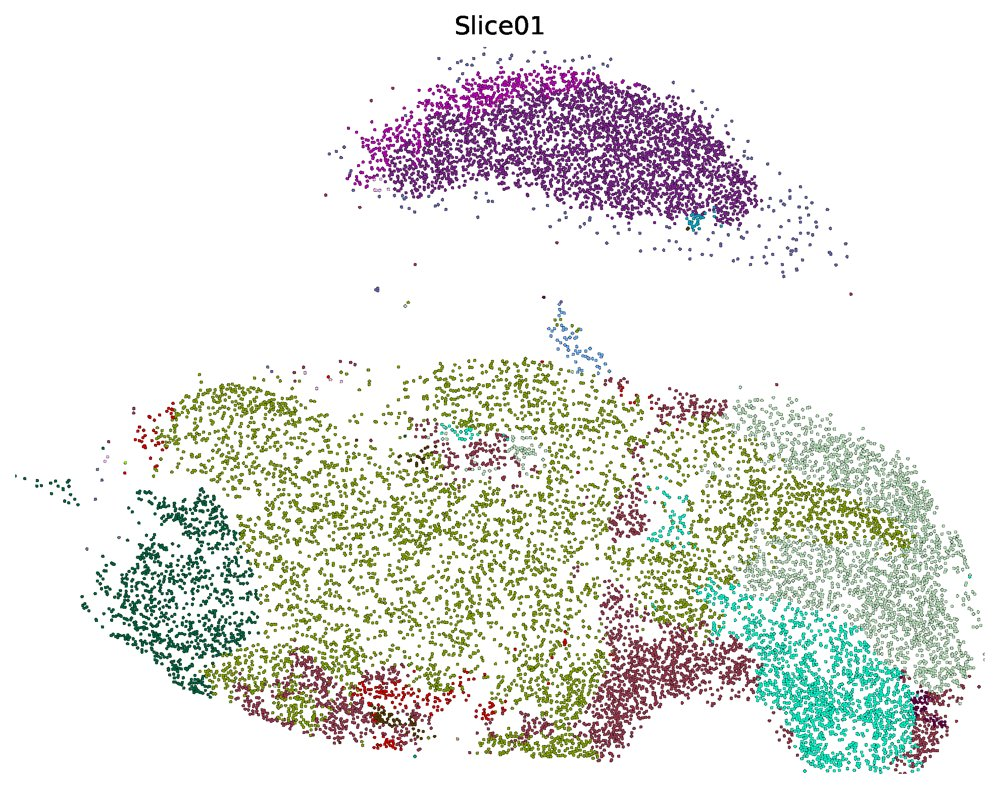

barseq, k = 252: showing 1 of 40 sections (all in /home/asriram/BARseq_Modular_CT2/runs/20261002T101500Z-252764/domains/barseq_cluster_plots_k252)


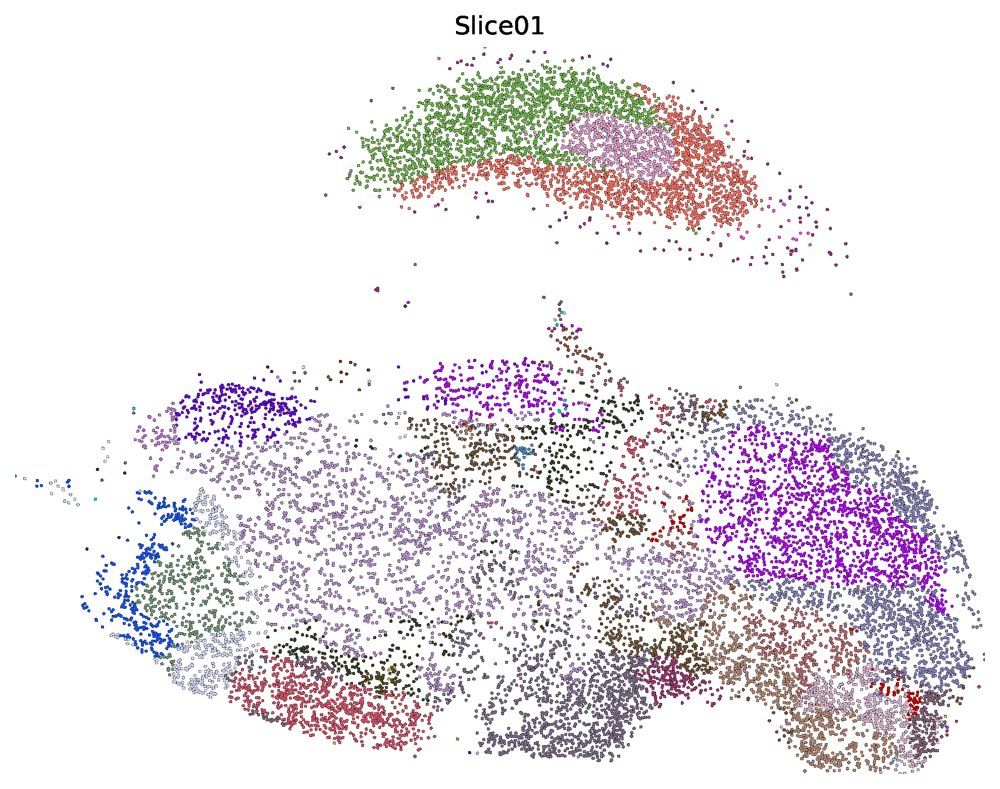

barseq, k = 564: showing 1 of 40 sections (all in /home/asriram/BARseq_Modular_CT2/runs/20261002T101500Z-252764/domains/barseq_cluster_plots_k564)


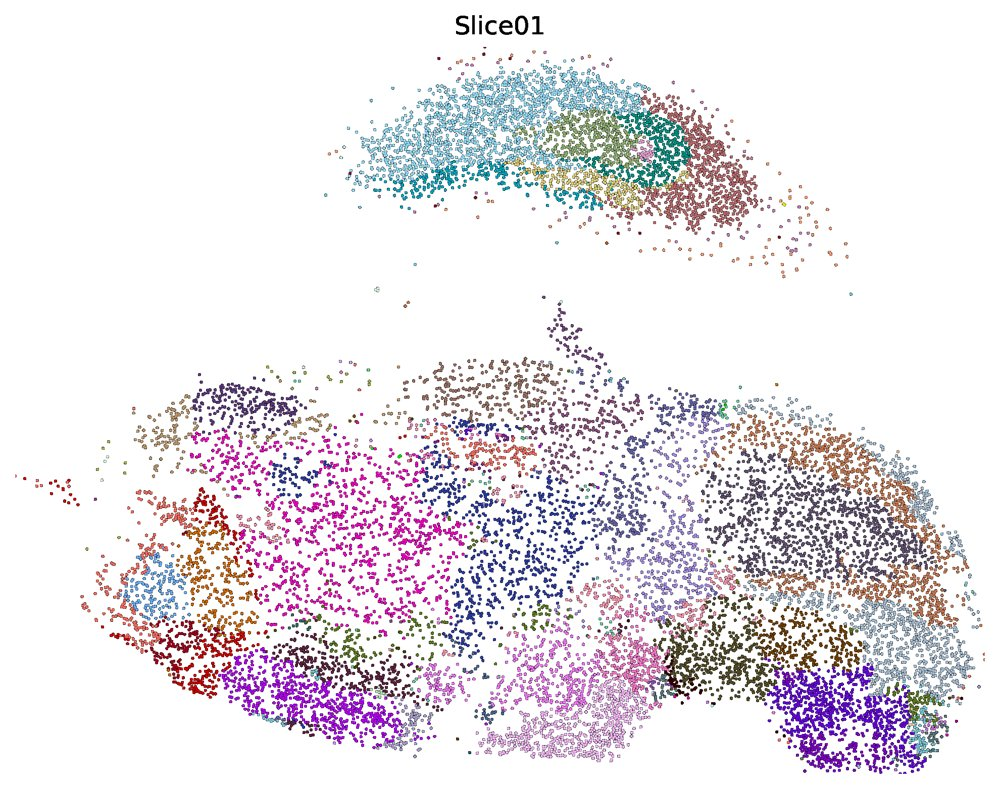

barseq_smoothed, k = 63: showing 1 of 40 sections (all in /home/asriram/BARseq_Modular_CT2/runs/20261002T101500Z-252764/domains/barseq_smoothed_cluster_plots_k63)


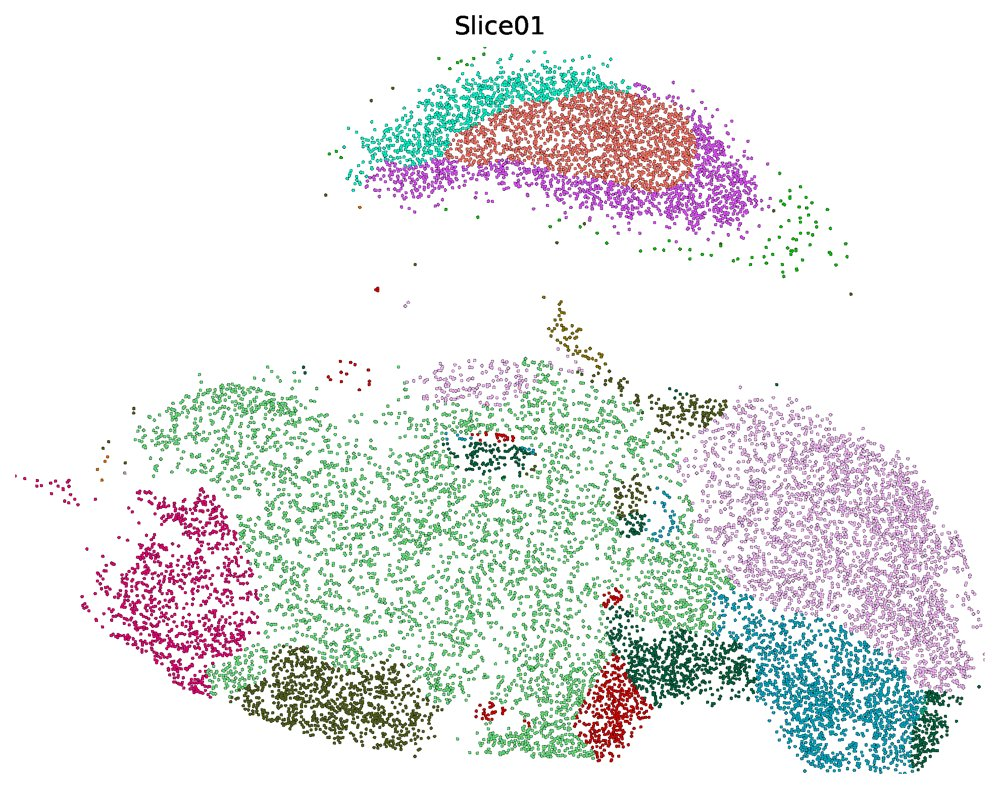

barseq_smoothed, k = 252: showing 1 of 40 sections (all in /home/asriram/BARseq_Modular_CT2/runs/20261002T101500Z-252764/domains/barseq_smoothed_cluster_plots_k252)


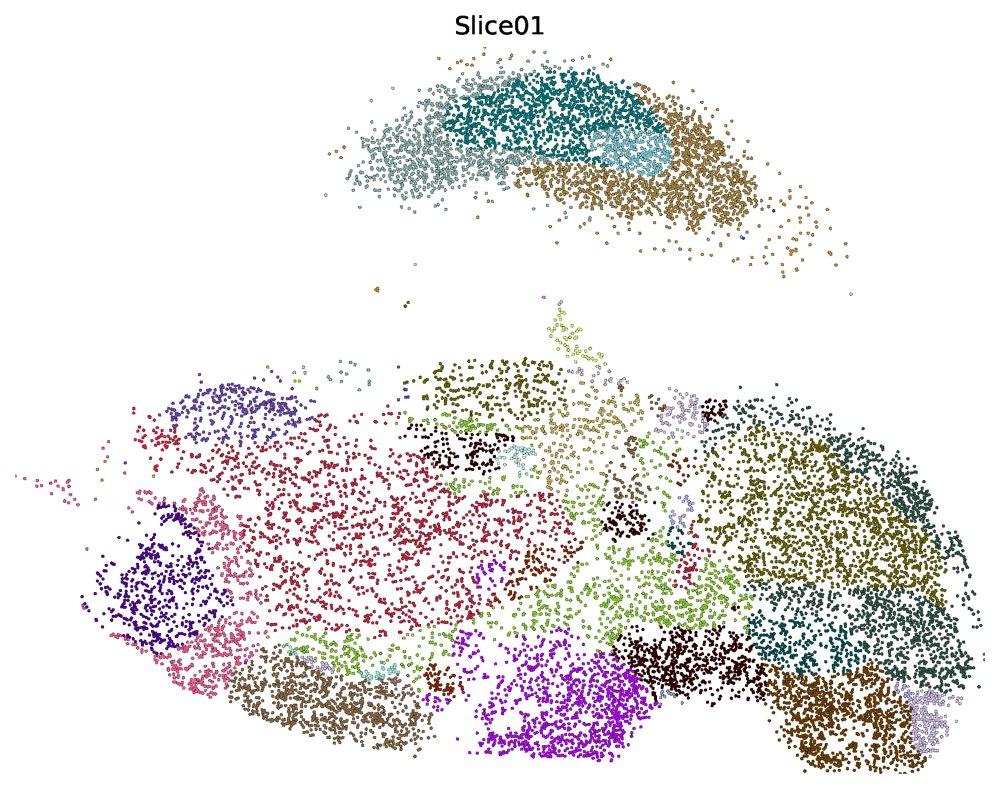

barseq_smoothed, k = 564: showing 1 of 40 sections (all in /home/asriram/BARseq_Modular_CT2/runs/20261002T101500Z-252764/domains/barseq_smoothed_cluster_plots_k564)


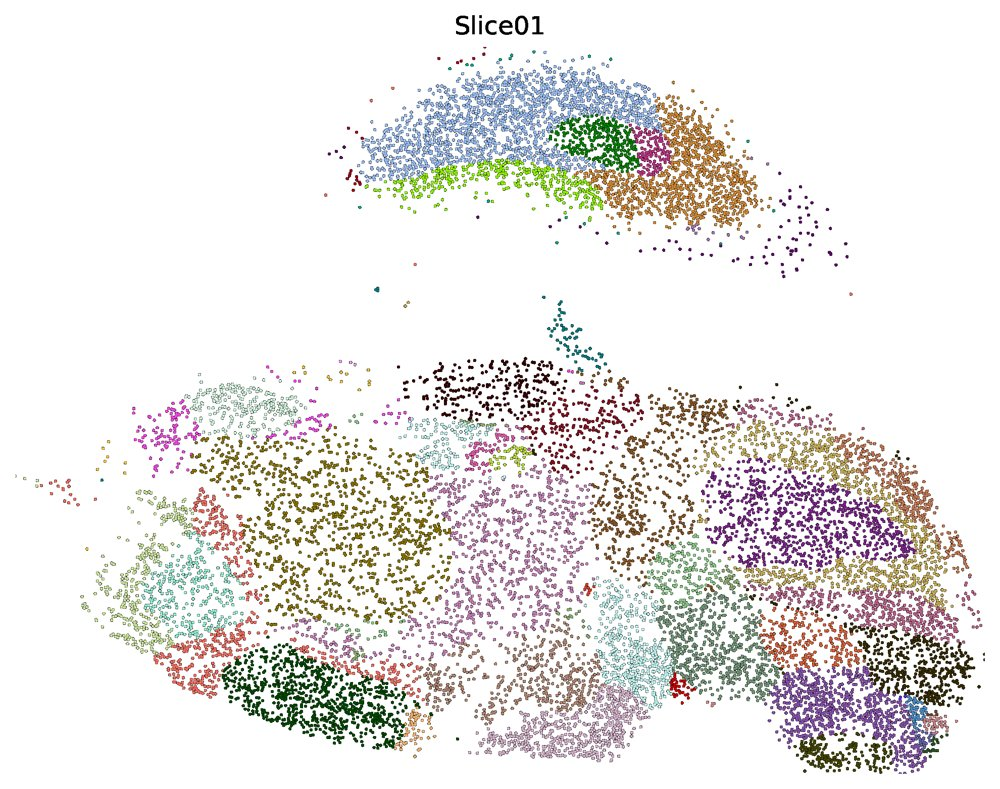

In [17]:
helper.show_domain_plots(DOMAINS_DIR, EMBEDDING_SETS, KS, n_show=1)

## Step 13: generate the HTML report (optional)
● TIMING ~1 min

Run this after Steps 9–11 have finished. It reads the saved assignments and writes a new,
self-contained `review.html` and `results.zip` under `WORK_DIR/html_reports/`. It does not retrain,
extract, smooth or cluster again. Training curves are recovered from the selected checkpoint's local
W&B history; missing values are reported rather than replaced with batch losses.

The report contains training diagnostics and maps for every section and k. If reference annotations
are supplied, it also shows reference–domain correspondence heatmaps: Pearson correlations between
cell-type proportions, with a fixed −1 to +1 color scale. Reference regions and discovered domains
need not have the same number of labels. The report has no separate composition-matrix panels.

The reporting functions are included in the installed CellTransformer2 package.
See the [reporting guide](../docs/notebook_html_report.md).
Section names come from the data. Set the report title, coordinate units and optional reference
columns below. To omit reference comparison, set `REFERENCE_COLUMNS = {}`. Reference rows are joined
by exact cell ID; a missing annotation excludes that cell from correspondence calculations, not from
training or the saved domain assignments. Colors are consistent across sections within each method
and k, but do not imply matched identities across methods or the reference.


In [18]:
from celltransformer.notebooks.reporting import report_from_notebook, read_reference_table, read_training_history, show_report

# REPLACE WITH YOUR DATA: display title, coordinate units and optional reference columns.
REPORT_NAME = 'BARseq pilot'
REPORT_COORD_UNITS = 'µm'
REFERENCE_FILE = RAW_METADATA
REFERENCE_ID_COLUMN = CELL_ID_COL
# The example uses CCF substructures. For other data, replace this mapping with
# {"Reference name": "your_annotation_column"}, or {} if there is no reference.
REFERENCE_COLUMNS = {'CCF depth 5': 'reference_depth5', 'CCF depth 7': 'reference_depth7', 'Released CCF regions': 'reference_released'}
REFERENCE_FOR_K = {63: 'CCF depth 5', 252: 'CCF depth 7', 564: 'Released CCF regions'}
REFERENCE_DISPLAY_NAMES = {'CCF depth 5': 'CCF', 'CCF depth 7': 'CCF', 'Released CCF regions': 'CCF'}

# Optional annotation-based enlargement; leave None for whole-section maps only.
# See the reporting guide linked above for explicit crop bounds and other reference layouts.
REPORT_CROP = None
REPORT_CROP_NAME = "Enlargement"
REPORT_BOUNDARY_GRID = None
REPORT_BOUNDARY_DISTANCE = None


In [19]:
# Read the completed checkpoint's local epoch averages; no W&B login is needed.
report_training = read_training_history(CHECKPOINT, expected_epochs=EPOCHS)
report_reference = read_reference_table(REFERENCE_FILE, REFERENCE_ID_COLUMN, REFERENCE_COLUMNS)

report_notes = report_training["notes"] + [
    f"{len(VALID_SECTIONS)} whole sections were withheld during training; clustering used all sections jointly.",
    "Reference correspondence is an exploratory comparison of cell-type composition, not an independent held-out clustering test.",
]
report_html = report_from_notebook(
    work_dir=WORK_DIR,
    embedding_sets=EMBEDDING_SETS,
    domains_dir=DOMAINS_DIR,
    ks=KS,
    dataset_name=REPORT_NAME,
    coordinate_units=REPORT_COORD_UNITS,
    n_genes=N_GENES,
    method_names={tag: "CellTransformer2 (+smoothing)" if Path(folder).resolve() == SMOOTHED_DIR.resolve()
                  else "CellTransformer2 (−smoothing)" for tag, folder in EMBEDDING_SETS.items()},
    reference_metadata=report_reference,
    reference_id_column=REFERENCE_ID_COLUMN,
    reference_columns=REFERENCE_COLUMNS,
    reference_for_k=REFERENCE_FOR_K if report_reference is not None else None,
    reference_display_names=REFERENCE_DISPLAY_NAMES,
    training_history=report_training["history"],
    notes=report_notes,
    provenance={"training": report_training["provenance"], "validation_sections": list(VALID_SECTIONS),
                "patch_size": PATCH_SIZE, "smoothing_sigma": SIGMA, "smoothing_neighbors": N_NEIGHBORS},
    crop_selection=REPORT_CROP if report_reference is not None else None,
    crop_name=REPORT_CROP_NAME,
    boundary_grid_size=REPORT_BOUNDARY_GRID,
    boundary_max_distance=REPORT_BOUNDARY_DISTANCE,
)
show_report(report_html)


2026-10-02 05:05:59 | Spatial map: Slice01, k=63


2026-10-02 05:06:00 | Spatial map: Slice02, k=63


2026-10-02 05:06:00 | Spatial map: Slice03, k=63


2026-10-02 05:06:00 | Spatial map: Slice04, k=63


2026-10-02 05:06:01 | Spatial map: Slice05, k=63


2026-10-02 05:06:01 | Spatial map: Slice06, k=63


... (120 outputs left out)

2026-10-02 05:06:44 | HTML REPORT COMPLETED: /home/asriram/BARseq_Modular_CT2/runs/20261002T101500Z-252764/html_reports/20261002T120559Z-253088/review.html


HTML: /home/asriram/BARseq_Modular_CT2/runs/20261002T101500Z-252764/html_reports/20261002T120559Z-253088/review.html
Results ZIP: /home/asriram/BARseq_Modular_CT2/runs/20261002T101500Z-252764/html_reports/20261002T120559Z-253088/results.zip
If the output is outside the notebook server directory, copy the printed HTML file to your local computer to open it.


/home/asriram/BARseq_Modular_CT2/runs/20261002T101500Z-252764/html_reports/20261002T120559Z-253088/review.html

/home/asriram/BARseq_Modular_CT2/runs/20261002T101500Z-252764/html_reports/20261002T120559Z-253088/results.zip

## Known limitations
- **GPU selection for smoothing and clustering.** `celltransformer-smooth` and `celltransformer-cluster` have no
  device option, so Steps 10–11 set `CUDA_VISIBLE_DEVICES` to the first GPU in `DEVICES`.
- **cuML kNN distances are imprecise at large coordinates** (up to ~4 µm at ~10,000 µm, from float32 rounding).
  Neighbor sets were identical on the example sections and smoothed embeddings differed by <1% per cell.